the PART 2 OF THE RTT waiting times performance analysis begins with the merging of the 12 cleaned datasets into one dataFrame

In [ ]:
import pandas as pd
import os
import glob
import matplotlib.pyplot as plt


files = glob.glob("../data/rtt_combined_sep25_aug26.csv")
print(len(files))   # should be 12

rtt = pd.concat([pd.read_csv(f, parse_dates=["period"]) for f in files], ignore_index=True)

print(rtt.shape)
print(rtt["period"].value_counts().sort_index())
print(rtt.groupby("period")["total_all"].sum().apply("{:,.0f}".format))

In [ ]:
print([c for c in rtt.columns if "provider" in c.lower() or "treatment" in c.lower()])

CELL 12 BELOW is a data quality check for the combined dataset 

In [ ]:
prov = "provider_org_code"        
tf   = "treatment_function_code"  

# Across all 12 months
print("Providers:", rtt[prov].nunique())
print("Treatment functions:", rtt[tf].nunique())

# Month by month (shows providers appearing or dropping out)
print(rtt.groupby("period")[[prov, tf]].nunique())

# August 2026 only – use these for the summary
aug = rtt[rtt["period"] == "2026-08-01"]
print("Aug providers:", aug[prov].nunique())
print("Aug treatment functions:", aug[tf].nunique())

# Codes with more than one name (catches renamed trusts)
name_col = "provider_org_name"    
names = rtt.groupby(prov)[name_col].nunique()
print(rtt[rtt[prov].isin(names[names > 1].index)][[prov, name_col]].drop_duplicates())

In [ ]:
renamed = names[names > 1]
print("Codes with more than one name:", len(renamed))

In [ ]:
latest = rtt.sort_values("period").groupby(prov)[name_col].last()
rtt["provider_name_latest"] = rtt[prov].map(latest)
rtt.to_csv("../data/rtt_combined_sep25_aug26.csv", index=False)

In [ ]:
#saving the combined dataset
rtt.to_csv("../data/rtt_combined_sep25_aug26.csv", index=False)

In [ ]:
latest[latest.duplicated(keep=False)]


How has NHS England’s performance against the 18-week referral-to-treatment standard changed between September 2025 and August 2026, and which specialties and providers account for the longest waits?

Sub-questions:

What percentage of patients waited under 18 weeks each month, and how far is that from the 92% target?
How has the number of 52+ week waiters changed?
Which specialties have the worst 18-week performance and the most long waiters?
How much does performance vary between trusts, and which are consistently best and worst?

18
            total_waiting   under_18  pct_under_18  gap_to_92
period                                                       
2025-09-01        7329574  4522668.0          61.7       30.3
2025-10-01        7337076  4523866.0          61.7       30.3
2025-11-01        7191310  4429395.0          61.6       30.4
2025-12-01        7231880  4440594.0          61.4       30.6
2026-01-01        7187677  4412147.0          61.4       30.6
2026-02-01        7156212  4472365.0          62.5       29.5
2026-03-01        7045510  4596622.0          65.2       26.8
2026-04-01        7123980  4623405.0          64.9       27.1
2026-05-01        7184233  4706017.0          65.5       26.5
2026-06-01        7178718  4721677.0          65.8       26.2
2026-07-01        7162692  4673731.0          65.3       26.7
2026-08-01        7189213  4684589.0          65.2       26.8


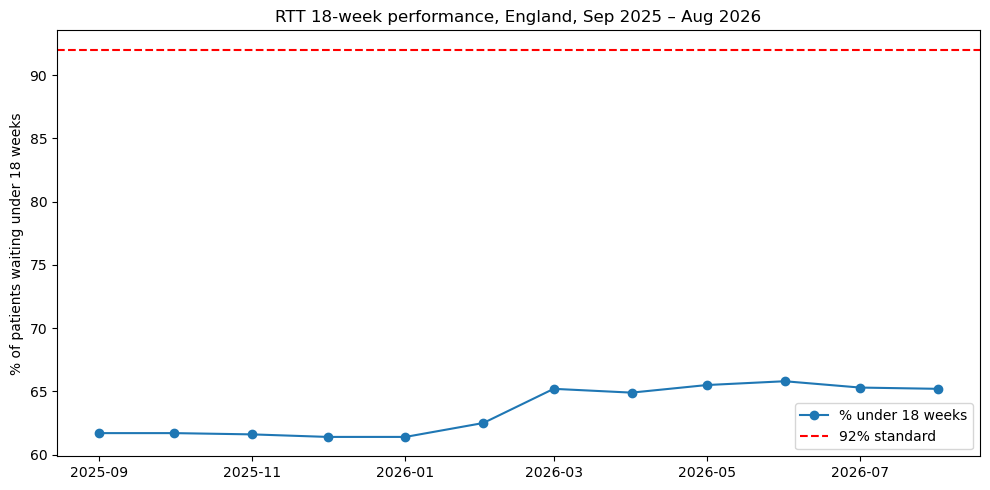

In [17]:

#what percentage of patients waited under 18 weeks each month, and how is the monthly performance
#against the 92% target?
week_cols = [c for c in rtt.columns if c.startswith("gt_")]
under18 = [c for c in week_cols if int(c.split("_")[1]) < 18]   # 0–18 week bands
print(len(under18))   # should be 18

monthly = rtt.groupby("period").agg(
    total_waiting=("total_all", "sum"),
    under_18=(under18[0], "sum")
)
monthly["under_18"] = rtt.groupby("period")[under18].sum().sum(axis=1)
monthly["pct_under_18"] = (monthly["under_18"] / monthly["total_waiting"] * 100).round(1)
monthly["gap_to_92"] = (92 - monthly["pct_under_18"]).round(1)
print(monthly)

# Chart
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index, monthly["pct_under_18"], marker="o", label="% under 18 weeks")
ax.axhline(92, color="red", linestyle="--", label="92% standard")
ax.set_ylabel("% of patients waiting under 18 weeks")
ax.set_title("RTT 18-week performance, England, Sep 2025 – Aug 2026")
ax.legend()
plt.tight_layout()
plt.show()

            52+ weeks  65+ weeks  78+ weeks  104+ weeks  total_waiting  \
2025-09-01     181947      14607       2540         507        7329574   
2025-10-01     174373      14440       2900         589        7337076   
2025-11-01     157710      11367       2755         593        7191310   
2025-12-01     142204       9393       2874         611        7231880   
2026-01-01     137320       9522       2947         576        7187677   
2026-02-01     124280       8829       2668         548        7156212   
2026-03-01      95824       6304       2335         499        7045510   
2026-04-01     100665       7702       2421         576        7123980   
2026-05-01     105697       8670       2410         576        7184233   
2026-06-01     106621       9693       2268         549        7178718   
2026-07-01     111429      10842       2617         576        7162692   
2026-08-01     112958      12488       2748         544        7189213   

            pct_52plus  
2025-09-01  

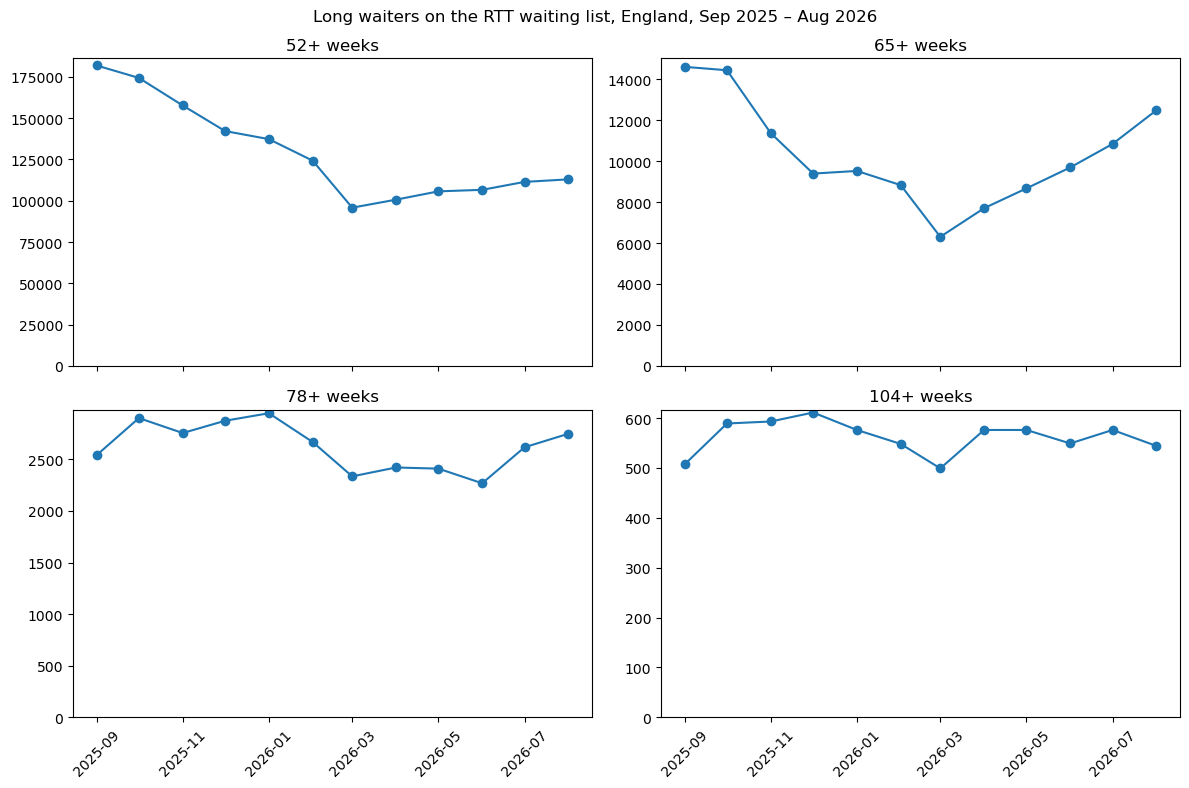

In [18]:
#How has the number of 52+ week waiters changed? 

def start_week(c):
    return int(c.split("_")[1])

thresholds = {"52+ weeks": 52, "65+ weeks": 65, "78+ weeks": 78, "104+ weeks": 104}

long_waits = pd.DataFrame(index=sorted(rtt["period"].unique()))
by_month = rtt.groupby("period")[week_cols].sum()

for label, wk in thresholds.items():
    cols = [c for c in week_cols if start_week(c) >= wk]
    long_waits[label] = by_month[cols].sum(axis=1)

long_waits["total_waiting"] = rtt.groupby("period")["total_all"].sum()
long_waits["pct_52plus"] = (long_waits["52+ weeks"] / long_waits["total_waiting"] * 100).round(2)
print(long_waits.astype({"52+ weeks": int, "65+ weeks": int, "78+ weeks": int, "104+ weeks": int}))

# Chart
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True)
for ax, label in zip(axes.flat, thresholds):
    ax.plot(long_waits.index, long_waits[label], marker="o")
    ax.set_title(label)
    ax.set_ylim(bottom=0)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Long waiters on the RTT waiting list, England, Sep 2025 – Aug 2026")
plt.tight_layout()
plt.show()

                                   total_waiting  pct_under_18  over_52  \
treatment_function_name                                                   
Oral Surgery Service                      316357          53.8   7544.0   
Ear Nose and Throat Service               590233          56.8  12031.0   
Plastic Surgery Service                   109605          59.4   3575.0   
Gynaecology Service                       586582          59.6  12885.0   
Trauma and Orthopaedic Service            851183          60.9  22043.0   
Neurosurgical Service                      54748          62.0    806.0   
Neurology Service                         208030          62.3   2078.0   
General Surgery Service                   384914          63.2   8213.0   
Urology Service                           367027          64.8   5222.0   
Other - Paediatric Services               322905          66.0   3931.0   
Other - Surgical Services                 474806          66.9   8197.0   
Cardiology Service       

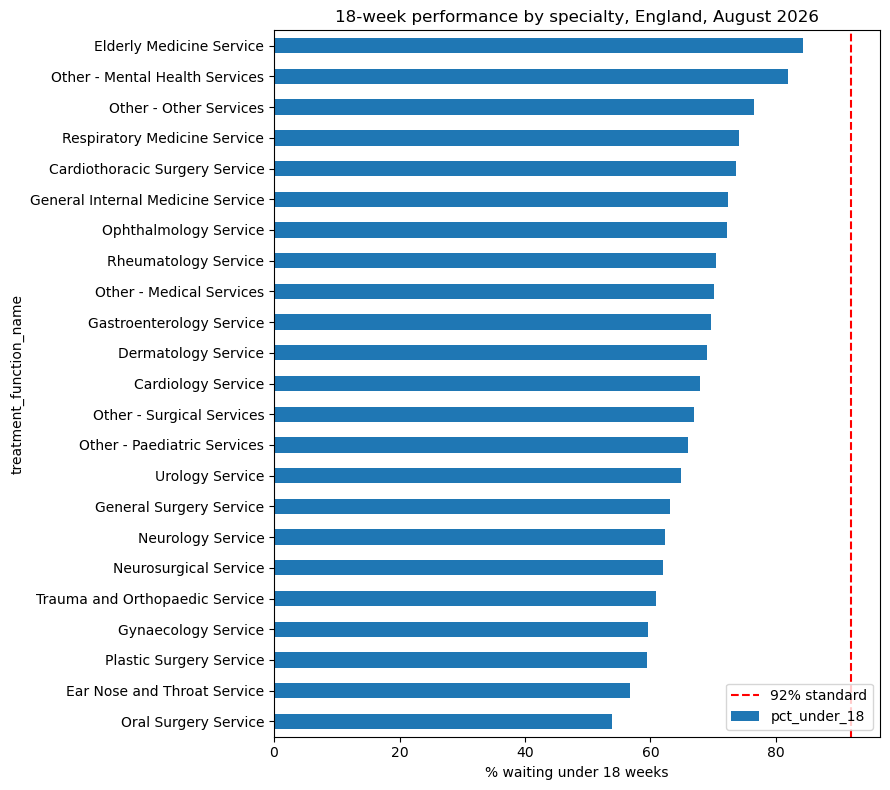

In [19]:
#Which specialties have the worst 18-week performance and the most long waiters?
by_spec = rtt.groupby(["period", "treatment_function_name"])

spec = pd.DataFrame({
    "total_waiting": by_spec["total_all"].sum(),
    "under_18": by_spec[under18].sum().sum(axis=1),
    "over_52": by_spec[[c for c in week_cols if start_week(c) >= 52]].sum().sum(axis=1),
}).reset_index()
spec["pct_under_18"] = (spec["under_18"] / spec["total_waiting"] * 100).round(1)

latest = spec[spec["period"] == spec["period"].max()].set_index("treatment_function_name")
first = spec[spec["period"] == spec["period"].min()].set_index("treatment_function_name")
latest["change_pct_pts"] = (latest["pct_under_18"] - first["pct_under_18"]).round(1)

print(latest.sort_values("pct_under_18")[["total_waiting", "pct_under_18", "over_52", "change_pct_pts"]])

# Chart: 18-week performance by specialty, Aug 2026
latest["pct_under_18"].sort_values().plot(kind="barh", figsize=(9, 8))
plt.axvline(92, color="red", linestyle="--", label="92% standard")
plt.xlabel("% waiting under 18 weeks")
plt.title("18-week performance by specialty, England, August 2026")
plt.legend()
plt.tight_layout()
plt.show()

130 providers
count    130.0
mean      65.8
std        6.7
min       50.4
25%       61.4
50%       65.1
75%       68.8
max       90.7
Name: pct_under_18, dtype: float64

BEST 10
                                         provider_org_name  total_waiting  pct_under_18  over_52
     MIDLANDS PARTNERSHIP UNIVERSITY NHS FOUNDATION TRUST          10166          90.7      0.0
                     SUSSEX COMMUNITY DERMATOLOGY SERVICE          20045          86.0    114.0
            CORA HEALTH MSK (FORMERLY CONNECT HEALTH LTD)          24720          85.5     74.0
             MOORFIELDS EYE HOSPITAL NHS FOUNDATION TRUST          42168          84.6     19.0
              NORTHUMBRIA HEALTHCARE NHS FOUNDATION TRUST          39301          83.6      0.0
     BIRMINGHAM COMMUNITY HEALTHCARE NHS FOUNDATION TRUST          15544          81.8      2.0
                     ROYAL BERKSHIRE NHS FOUNDATION TRUST          34597          80.7     35.0
TAMESIDE AND GLOSSOP INTEGRATED CARE NHS FOUNDATION T

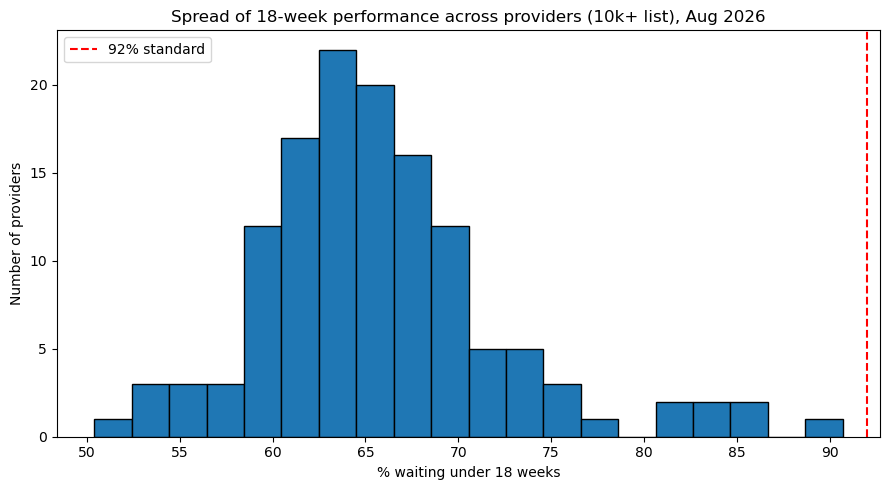

In [20]:
#How much does performance vary between trusts, and which are consistently best and worst?

by_prov = rtt.groupby(["period", "provider_org_code", "provider_org_name"])
prov = pd.DataFrame({
    "total_waiting": by_prov["total_all"].sum(),
    "under_18": by_prov[under18].sum().sum(axis=1),
    "over_52": by_prov[[c for c in week_cols if start_week(c) >= 52]].sum().sum(axis=1),
}).reset_index()
prov["pct_under_18"] = (prov["under_18"] / prov["total_waiting"] * 100).round(1)

# Latest month, larger providers only
aug = prov[(prov["period"] == prov["period"].max()) & (prov["total_waiting"] >= 10000)]
print(len(aug), "providers")
print(aug["pct_under_18"].describe().round(1))

cols = ["provider_org_name", "total_waiting", "pct_under_18", "over_52"]
print("\nBEST 10\n", aug.nlargest(10, "pct_under_18")[cols].to_string(index=False))
print("\nWORST 10\n", aug.nsmallest(10, "pct_under_18")[cols].to_string(index=False))

# Consistency: months each provider spent in the bottom quarter
big = prov[prov["provider_org_code"].isin(aug["provider_org_code"])].copy()
big["bottom_q"] = big.groupby("period")["pct_under_18"].transform(lambda x: x <= x.quantile(0.25))
persistent = big.groupby("provider_org_name")["bottom_q"].sum().sort_values(ascending=False)
print("\nMonths in bottom quarter (of 12)\n", persistent.head(10))

# Chart: spread of performance
plt.figure(figsize=(9, 5))
plt.hist(aug["pct_under_18"], bins=20, edgecolor="black")
plt.axvline(92, color="red", linestyle="--", label="92% standard")
plt.xlabel("% waiting under 18 weeks")
plt.ylabel("Number of providers")
plt.title("Spread of 18-week performance across providers (10k+ list), Aug 2026")
plt.legend()
plt.tight_layout()
plt.show()

In [21]:
#ranking providers within one specialty; trauma and orthopaedic
TO = rtt[rtt["treatment_function_name"] == "Trauma and Orthopaedic Service"]

by_to = TO.groupby(["period", "provider_org_code", "provider_org_name"])
to = pd.DataFrame({
    "total_waiting": by_to["total_all"].sum(),
    "under_18": by_to[under18].sum().sum(axis=1),
    "over_52": by_to[[c for c in week_cols if start_week(c) >= 52]].sum().sum(axis=1),
}).reset_index()
to["pct_under_18"] = (to["under_18"] / to["total_waiting"] * 100).round(1)

# Latest month, providers with 2,000+ T&O patients waiting
to_aug = to[(to["period"] == to["period"].max()) & (to["total_waiting"] >= 2000)]
print(len(to_aug), "providers")
print(to_aug["pct_under_18"].describe().round(1))

cols = ["provider_org_name", "total_waiting", "pct_under_18", "over_52"]
print("\nBEST 10 (T&O)\n", to_aug.nlargest(10, "pct_under_18")[cols].to_string(index=False))
print("\nWORST 10 (T&O)\n", to_aug.nsmallest(10, "pct_under_18")[cols].to_string(index=False))

# Persistence: months in bottom quarter for T&O
big_to = to[to["provider_org_code"].isin(to_aug["provider_org_code"])].copy()
big_to["bottom_q"] = big_to.groupby("period")["pct_under_18"].transform(lambda x: x <= x.quantile(0.25))
persist_to = big_to.groupby("provider_org_name")["bottom_q"].sum()
print("\nProviders in bottom quarter all 12 months:", (persist_to == 12).sum())
print(persist_to[persist_to == 12].sort_index())

# Do the same trusts appear in both rankings?
overall_persistent = set(persistent[persistent == 12].index)
to_persistent = set(persist_to[persist_to == 12].index)
print("\nPersistently poor overall AND in T&O:\n", sorted(overall_persistent & to_persistent))

130 providers
count    130.0
mean      61.2
std       11.4
min       28.7
25%       53.3
50%       59.8
75%       67.3
max       99.7
Name: pct_under_18, dtype: float64

BEST 10 (T&O)
                                           provider_org_name  total_waiting  pct_under_18  over_52
                 KENT COMMUNITY HEALTH NHS FOUNDATION TRUST           3828          99.7      0.0
            LANCASHIRE & SOUTH CUMBRIA NHS FOUNDATION TRUST           2778          87.1      0.0
         SOUTH WARWICKSHIRE UNIVERSITY NHS FOUNDATION TRUST           3614          85.6      0.0
             NORTH TEES AND HARTLEPOOL NHS FOUNDATION TRUST           7078          85.1     17.0
HAMPSHIRE AND ISLE OF WIGHT HEALTHCARE NHS FOUNDATION TRUST           3659          83.2      0.0
                      SHROPSHIRE COMMUNITY HEALTH NHS TRUST           7287          82.9      1.0
                       ROYAL BERKSHIRE NHS FOUNDATION TRUST           2231          82.9      3.0
                               

CELL 18 prepares the combined dataset for export into Power BI, by trimming the week bands and reducing the number of columns to 13

In [22]:
#Power Bi export. Trim the 105 week-band to a slimer version before exporting to power BI
#summarise the columns

pbi = rtt[["period", "provider_org_code", "provider_org_name",
           "commissioner_org_code", "commissioner_org_name",
           "treatment_function_code", "treatment_function_name", "total_all"]].copy()

pbi["under_18"] = rtt[under18].sum(axis=1)
for label, wk in {"over_52": 52, "over_65": 65, "over_78": 78, "over_104": 104}.items():
    pbi[label] = rtt[[c for c in week_cols if start_week(c) >= wk]].sum(axis=1)

pbi.to_csv("../data/rtt_combined_sep25_aug26.csv", index=False)
print(pbi.shape)   # reduces to 13 colums

(615185, 13)


THE CELL below is the Statistical process control checks 

Baseline mean 61.55%, UCL 61.76%, LCL 61.33%, average MR 0.08

Outside control limits:
 period
2026-02-01    62.50
2026-03-01    65.24
2026-04-01    64.90
2026-05-01    65.50
2026-06-01    65.77
2026-07-01    65.25
2026-08-01    65.16
dtype: float64

Longest run above baseline mean: 7 months (7+ = shift)


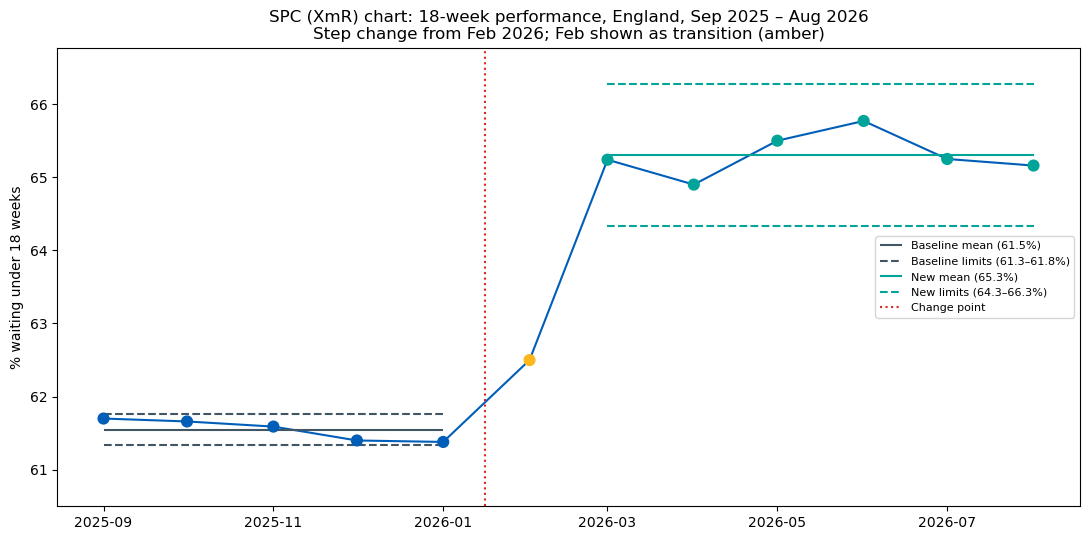

Baseline: mean 61.55%, limits 61.33–61.76%
New:      mean 65.30%, limits 64.34–66.27%
Step change: +3.8 percentage points


In [23]:
# SPC

import matplotlib.pyplot as plt

# Monthly % within 18 weeks
week_cols = [c for c in rtt.columns if c.startswith("gt_")]
under18 = [c for c in week_cols if int(c.split("_")[1]) < 18]
m = rtt.groupby("period")[under18 + ["total_all"]].sum()
pct = (m[under18].sum(axis=1) / m["total_all"] * 100).round(2)

# Baseline: months before the change
baseline = pct[pct.index < "2026-02-01"]
mean = baseline.mean()
mr_bar = baseline.diff().abs().mean()          # average moving range
ucl = mean + 2.66 * mr_bar                     # standard XmR constant
lcl = mean - 2.66 * mr_bar
print(f"Baseline mean {mean:.2f}%, UCL {ucl:.2f}%, LCL {lcl:.2f}%, average MR {mr_bar:.2f}")

# Rule 1: points outside the limits
outside = pct[(pct > ucl) | (pct < lcl)]
print("\nOutside control limits:\n", outside)

# Rule 2: run of 7+ points above the baseline mean
run, longest = 0, 0
for v in pct:
    run = run + 1 if v > mean else 0
    longest = max(longest, run)
print(f"\nLongest run above baseline mean: {longest} months (7+ = shift)")

# Chart
new = pct[pct.index >= "2026-03-01"]
new_mean = new.mean()
new_mr = new.diff().abs().mean()
new_ucl, new_lcl = new_mean + 2.66 * new_mr, new_mean - 2.66 * new_mr

base_start, base_end = baseline.index.min(), baseline.index.max()
new_start, new_end = new.index.min(), new.index.max()

fig, ax = plt.subplots(figsize=(11, 5.5))
colours = ["#005EB8" if d <= base_end else ("#FFB81C" if d < new_start else "#00A499") for d in pct.index]
ax.plot(pct.index, pct.values, color="#005EB8", linewidth=1.5)
ax.scatter(pct.index, pct.values, color=colours, s=60, zorder=3)

# Baseline phase (Sep 2025 – Jan 2026)
ax.hlines(mean, base_start, base_end, color="#425563", label=f"Baseline mean ({mean:.1f}%)")
ax.hlines([ucl, lcl], base_start, base_end, color="#425563", linestyle="--",
          label=f"Baseline limits ({lcl:.1f}–{ucl:.1f}%)")

# New phase (Mar – Aug 2026)
ax.hlines(new_mean, new_start, new_end, color="#00A499", label=f"New mean ({new_mean:.1f}%)")
ax.hlines([new_ucl, new_lcl], new_start, new_end, color="#00A499", linestyle="--",
          label=f"New limits ({new_lcl:.1f}–{new_ucl:.1f}%)")

ax.axvline(pd.Timestamp("2026-01-16"), color="#DA291C", linestyle=":", label="Change point")
ax.set_ylim(60.5, max(new_ucl, pct.max()) + 0.5)
ax.set_ylabel("% waiting under 18 weeks")
ax.set_title("SPC (XmR) chart: 18-week performance, England, Sep 2025 – Aug 2026\n"
             "Step change from Feb 2026; Feb shown as transition (amber)")
ax.legend(loc="center right", fontsize=8)
plt.tight_layout()
plt.savefig("../images/spc_18week.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Baseline: mean {mean:.2f}%, limits {lcl:.2f}–{ucl:.2f}%")
print(f"New:      mean {new_mean:.2f}%, limits {new_lcl:.2f}–{new_ucl:.2f}%")
print(f"Step change: +{new_mean - mean:.1f} percentage points")

In [24]:
#SPC TABLE
import numpy as np

spc = pd.DataFrame({"period": pct.index, "pct": pct.values / 100})

base_mask = spc["period"] <= base_end
new_mask = spc["period"] >= new_start

for col, val_base, val_new in [("mean", mean, new_mean), ("ucl", ucl, new_ucl), ("lcl", lcl, new_lcl)]:
    spc[f"base_{col}"] = np.where(base_mask, val_base / 100, np.nan)
    spc[f"new_{col}"] = np.where(new_mask, val_new / 100, np.nan)

spc["phase"] = np.select([base_mask, new_mask], ["Baseline", "New process"], "Transition")
spc.to_csv("../data/rtt_combined_sep25_aug26.csv", index=False)
print(spc)

       period     pct  base_mean  new_mean  base_ucl   new_ucl  base_lcl  \
0  2025-09-01  0.6170    0.61546       NaN  0.617588       NaN  0.613332   
1  2025-10-01  0.6166    0.61546       NaN  0.617588       NaN  0.613332   
2  2025-11-01  0.6159    0.61546       NaN  0.617588       NaN  0.613332   
3  2025-12-01  0.6140    0.61546       NaN  0.617588       NaN  0.613332   
4  2026-01-01  0.6138    0.61546       NaN  0.617588       NaN  0.613332   
5  2026-02-01  0.6250        NaN       NaN       NaN       NaN       NaN   
6  2026-03-01  0.6524        NaN  0.653033       NaN  0.662716       NaN   
7  2026-04-01  0.6490        NaN  0.653033       NaN  0.662716       NaN   
8  2026-05-01  0.6550        NaN  0.653033       NaN  0.662716       NaN   
9  2026-06-01  0.6577        NaN  0.653033       NaN  0.662716       NaN   
10 2026-07-01  0.6525        NaN  0.653033       NaN  0.662716       NaN   
11 2026-08-01  0.6516        NaN  0.653033       NaN  0.662716       NaN   

     new_lc